# Readmission 2026 — Extended Analysis (AACAP)

Tiered inferential analysis on the **complete cohort (N = 2,652 patients; per-patient 90-day (post-discharge)
readmission 9.3%)**, plus a **preliminary-subset** readmission-timing and provider analysis.

**Statistical tiers**
1. **Bivariate inferential** — each association with an explicit test + figure
2. **Subgroup descriptive** — diagnosis subgroups (visit / chronic / non-suicidal) vs four outcomes
3. **Multivariate inferential** — adjusted logistic & linear regression
4. **Readmission windows & readmission LOS** — *preliminary subset* (XLSX, N≈1,920; 1,206 linked)
5. **Psychiatrist vs NP** — *preliminary subset*, exploratory (n=26 NP)
6. **ML / predictive** — Random Forest & CatBoost with new features

> Tests follow the project's idioms: Mann-Whitney U (skewed LOS / continuous-by-group), Spearman
> (continuous-continuous), chi-square (categorical), Kruskal-Wallis (>2 groups), `statsmodels`
> logistic/OLS for adjusted models. Multi-hypothesis families are FDR (Benjamini-Hochberg) corrected.
> LOS is right-skewed, so medians (IQR) and non-parametric tests are primary.


In [1]:
# ── Imports & style ──────────────────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import os, json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

plt.rcParams.update({'font.size':12,'axes.titlesize':14,'figure.dpi':120,'savefig.dpi':200,'savefig.bbox':'tight'})
BLUE, ORANGE, GREEN, RED, PURPLE = '#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3'
sns.set_style('whitegrid')
os.makedirs('figures', exist_ok=True)
ROOT = '.'
print('✓ libraries loaded')

/Users/matthewgold/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/r7/sbbjx0ls4mqck4f3x1qfjkn00000gn/T/matplotlib-e1gayiwt because there was an issue with the default path (/Users/matthewgold/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


✓ libraries loaded


## Preamble — load complete cohort & engineer features
(mirrors Part 1; this notebook stands alone)

In [2]:
# ── Load complete cohort (N=2,652) + feature engineering ─────────────────────
df = pd.read_csv('data/annotated_psychiatric_data_complete.csv')
df['readmitted'] = (pd.to_numeric(df['Readmissions'], errors='coerce').fillna(0) > 0).astype(int)
df['age'] = pd.to_numeric(df['Pt_Age_Visit'], errors='coerce')
df['gender'] = df['GenderCode'].str.strip().str.title()
df['gender_male'] = (df['GenderCode'].str.strip().str.lower()=='male').astype(int)
df['insurance_public'] = df['Insurance'].str.contains('AHCCCS', case=False, na=False).astype(int)
df['insurance_cat'] = np.where(df['insurance_public']==1,'Public (AHCCCS)','Commercial/Other')
df['ace_score'] = pd.to_numeric(df['ACEscore'], errors='coerce')
df['ace_high'] = (df['ace_score']>=4).astype(float)
df['restraint_n'] = pd.to_numeric(df['restraints'], errors='coerce').fillna(0)
df['had_restraints'] = (df['restraint_n']>0).astype(int)
df['csrss_yellow'] = df['Yellow flags (C-SRSS)'].notna().astype(int)   # NOTE: 'C-SRSS' typo is in the source CSV
df['csrss_orange'] = df['Orange flags (C-SSRS)'].notna().astype(int)
df['csrss_red']    = df['Red flags (C-SSRS)'].notna().astype(int)
df['csrss_any']    = ((df['csrss_yellow']+df['csrss_orange']+df['csrss_red'])>0).astype(int)
df['csrss_level']  = np.select([df['csrss_red']==1, df['csrss_orange']==1, df['csrss_yellow']==1],[3,2,1],default=0)
df['csrss_label']  = df['csrss_level'].map({0:'None',1:'Yellow',2:'Orange',3:'Red'})
df['VisitDate'] = pd.to_datetime(df['VisitDate'], errors='coerce')
df['DischDate'] = pd.to_datetime(df['DischDate'], errors='coerce')
df['los_days']  = (df['DischDate']-df['VisitDate']).dt.days

def count_csv(s):
    return 0 if pd.isna(s) or str(s).strip()=='' else len([x for x in str(s).split(',') if x.strip()])
def uniq_dsm5(row):
    cats=set()
    for col in ['VisitDiags_DSM5Categories','ChronicDiags_DSM5Categories']:
        v=row.get(col,'')
        if pd.notna(v) and str(v).strip(): cats.update(c.strip() for c in str(v).split(';') if c.strip())
    return len(cats)
df['n_dsm5_categories'] = df.apply(uniq_dsm5, axis=1)
all_dsm5 = (df['VisitDiags_DSM5Categories'].fillna('')+';'+df['ChronicDiags_DSM5Categories'].fillna('')).str.lower()
CATEGORY_FLAGS = {'has_nssi':'non-suicidal self-injury','has_trauma':'trauma and stressor','has_adhd':'adhd',
 'has_asd':'autism spectrum','has_conduct':'conduct disorder','has_depression':'depressive disorders',
 'has_anxiety':'anxiety disorders','has_bipolar':'bipolar','has_psychotic':'psychotic',
 'has_intellectual':'intellectual disability','has_ocd':'obsessive-compulsive'}
for f,kw in CATEGORY_FLAGS.items(): df[f]=all_dsm5.str.contains(kw,na=False).astype(int)

# Part B: neurocognitive flag (organic codes that PyHealth CCS routes to 'residual; unclassified')
NEURO_CODES = ['F02.80','F0280','F03.91','F0391','F05','F07.81','F0781','F09']
allcodes = (df['VisitDiags'].fillna('')+','+df['ChronicDiags'].fillna('')+','+df['NonSuicidialDiags'].fillna('')).str.upper()
df['has_neurocognitive'] = (all_dsm5.str.contains('neurocognitive',na=False) |
                            allcodes.apply(lambda s: any(c in s for c in NEURO_CODES))).astype(int)

# Suicidality measured via ICD CODE (R45.851 suicidal ideation) — the operationalization the original
# 2025 analysis used. This is DISTINCT from the C-SSRS flag columns (csrss_*), which capture a
# different construct; the two are analyzed separately throughout. A suicide-attempt/history flag is
# also derived (T14.91 self-harm injury; Z91.5 personal history of self-harm).
df['has_suicidal_ideation'] = allcodes.str.contains('R45.851', regex=False).astype(int)
df['has_suicide_attempt']   = allcodes.str.contains(r'T14\.91|Z91\.5', regex=True).astype(int)

# ── Diagnostic complexity — TWO distinct measures (these are NOT the same thing) ──────────────
#   n_dsm5_categories   = number of distinct DSM-5 *categories* (e.g. 'Depressive Disorders') — coarse
#   n_distinct_diagnoses = number of distinct *ICD-10 codes* across all three diagnosis columns — granular
def _distinct_codes(row):
    s=set()
    for col in ['VisitDiags','NonSuicidialDiags','ChronicDiags']:
        v=row.get(col,'')
        if pd.notna(v) and str(v).strip():
            s.update(t.strip().upper() for t in str(v).split(',') if t.strip())
    return len(s)
df['n_distinct_diagnoses']=df.apply(_distinct_codes,axis=1)

# ── Medical comorbidity (Feudtner Pediatric CCC-aligned) ────────────────────────────────────
# Allowlist of ICD-10 chapters that correspond to Feudtner CCC categories (BMC Pediatrics 2014):
#   C=Neoplasm, D=Blood, E=Endocrine/metabolic, G=Neurological, H=Eye/ear,
#   I=Cardiovascular, J=Respiratory, K=Digestive, L=Skin, M=Musculoskeletal,
#   N=Genitourinary, Q=Congenital.
# Excludes: F (psychiatric), Z (social/admin proxies), R (symptoms/signs — unconfirmed),
#   A/B (infectious — typically acute), P (perinatal), S/T/V-Y (injury/external cause).
_CCC_CHAPTERS = frozenset('CDEGHIJKLMNQ')
def _has_ccc(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return 0
    tokens = [t.strip().upper() for t in str(codes).split(',') if t.strip()]
    return int(any(t and t[0] in _CCC_CHAPTERS for t in tokens))
df['has_medical_comorbidity'] = df['ChronicDiags'].apply(_has_ccc)

# ── ACE-Associated Health Conditions (ACEs Aware pediatric algorithm) ────────────────────────
#   Physical/somatic AAHCs detectable by ICD prefix. We deliberately EXCLUDE the psychiatric AAHCs
#   (depression/ADHD/anxiety/conduct/suicidal ideation) because in this psychiatric inpatient cohort
#   they are near-universal (~96%) and are the admission diagnoses themselves — including them would
#   make 'high ACE' circular and ~90% prevalent. Physical AAHCs give a meaningful ~33% flag.
PHYS_AAHC = {
 'Asthma':('J45',),'Overweight/obesity':('E66','Z684'),'Allergy/atopy':('J30','T784'),
 'Eczema/dermatitis':('L20','L21','L23','L24','L25','L27','L28','L30'),'Urticaria':('L50',),
 'Headache/migraine':('R51','G43','G44'),'Somatic symptoms':('R10','R11','R42','K59'),
 'Sleep disturbance':('G47',),'Enuresis/encopresis':('N3944','R32','F980','R15','F981'),
 'Failure to thrive':('R6251','R627','R633'),
}
_norm = allcodes.str.replace('.','',regex=False)
def _has_prefix(prefixes):
    return pd.Series([any(any(t.startswith(p) for t in s.split(',')) for p in prefixes) for s in _norm], index=df.index)
ace_cond_flags = pd.DataFrame({name:_has_prefix(pfx) for name,pfx in PHYS_AAHC.items()})
df['has_ace_condition'] = (ace_cond_flags.sum(axis=1)>0).astype(int)               # physical AAHC present
# full-list version (incl. psychiatric AAHCs) — kept only to demonstrate why it is unusable here
df['has_ace_condition_full'] = ((df['has_ace_condition']==1) |
    allcodes.str.contains('F32|F33|F34|F40|F41|F90|F91|R45.851', regex=True)).astype(int)

# ACEs Aware PEDIATRIC risk tier: Low=ACE 0; High=ACE>=4 OR (ACE 1-3 WITH a physical AAHC);
# Intermediate=ACE 1-3 without. (Computed only where ACE is recorded.)
def _ace_tier(a, cond):
    if pd.isna(a): return np.nan
    if a==0: return 'Low'
    if a>=4: return 'High'
    return 'High' if cond==1 else 'Intermediate'
df['ace_risk_tier']=[_ace_tier(a,c) for a,c in zip(df['ace_score'],df['has_ace_condition'])]
df['high_ace_expanded']=df['ace_risk_tier'].map({'Low':0,'Intermediate':0,'High':1})   # NaN where ACE missing

N=len(df)
print(f'N={N} | readmit={df.readmitted.sum()} ({df.readmitted.mean()*100:.1f}%) | ACE avail={df.ace_score.notna().sum()} '
      f'| LOS median={df.los_days.median():.0f} | neurocognitive={df.has_neurocognitive.sum()} '
      f'| suicidal-ideation(ICD)={df.has_suicidal_ideation.sum()} ({df.has_suicidal_ideation.mean()*100:.0f}%)')

N=2652 | readmit=246 (9.3%) | ACE avail=1569 | LOS median=8 | neurocognitive=8 | suicidal-ideation(ICD)=1346 (51%)


In [3]:
# ── Statistical helpers ──────────────────────────────────────────────────────
def pstr(p): return '<0.001' if (pd.notna(p) and p<0.001) else (f'{p:.3f}' if pd.notna(p) else 'n/a')
def mwu(a,b):
    a=pd.Series(a).dropna(); b=pd.Series(b).dropna()
    if len(a)<3 or len(b)<3: return dict(n1=len(a),n2=len(b),med1=a.median(),med2=b.median(),U=np.nan,p=np.nan)
    U,p=stats.mannwhitneyu(a,b,alternative='two-sided')
    return dict(n1=len(a),n2=len(b),med1=a.median(),med2=b.median(),U=U,p=p)
def spear(a,b):
    d=pd.DataFrame({'a':a,'b':b}).dropna()
    r,p=stats.spearmanr(d['a'],d['b']); return dict(n=len(d),rho=r,p=p)
def chi2(a,b):
    tab=pd.crosstab(a,b); c,p,dof,_=stats.chi2_contingency(tab); return dict(p=p,chi2=c,dof=dof,tab=tab)
def kruskal(groups):
    gs=[pd.Series(g).dropna() for g in groups]; gs=[g for g in gs if len(g)>=3]
    H,p=stats.kruskal(*gs); return dict(H=H,p=p,k=len(gs))
def odds_ratio_2x2(flag, outcome):
    # logistic univariate OR for binary flag vs binary outcome
    try:
        m=smf.logit(f'{outcome} ~ flag', data=pd.DataFrame({'flag':flag.astype(float),outcome:df[outcome].values})).fit(disp=0)
        return np.exp(m.params['flag']), m.pvalues['flag']
    except Exception:
        return np.nan, np.nan
print('✓ helpers ready')

✓ helpers ready


## §0Z — Z-code covariance analysis
`has_z_code` (any Z-chapter ICD code in diagnoses) is included as a predictor in the multivariable
readmission model. This section verifies it is not merely a proxy for `ace_score` or `has_trauma`
before reporting it as a distinct social-risk signal.

**Decision rule:** Spearman(ace_score, has_z_code) > 0.40 → note Z-code partially captures ACE burden.
Spearman < 0.40 → report as a distinct social-risk signal (independent of ACE).


has_z_code prevalence: 46.5% (n=1232)

Z-code × Trauma cross-tab:
  Z+Trauma:  762   Z only:    470
  Trauma only: 662   Neither: 758
  Phi(has_z_code, has_trauma) = 0.152

Spearman correlations (n=1569 for ACE-based):
  rho(ace_score, has_z_code)  = 0.109  (p=<0.001)
  rho(ace_score, has_trauma)  = 0.396  (p=<0.001)
  rho(has_z_code, has_trauma) = 0.152  (p=<0.001) (n=2652)

INTERPRETATION: rho(ace_score, has_z_code) <= 0.40.
  Z-code is a DISTINCT social-risk signal, independent of ACE score.
  Safe to report as: 'Z-code presence (any Z-chapter social/administrative code)
   represents a distinct social-risk dimension, not a proxy for ACE burden.'

Top Z-codes by frequency:
   code   n  readmit_pct                                   description
  Z65.8 224         11.5 Other specified problems related to psychosoc
Z62.820 200          9.3               Parent-child relational problem
  Z63.5 192         10.9 Disruption of family by separation and divorc
 Z62.21 182         10.8     Ch

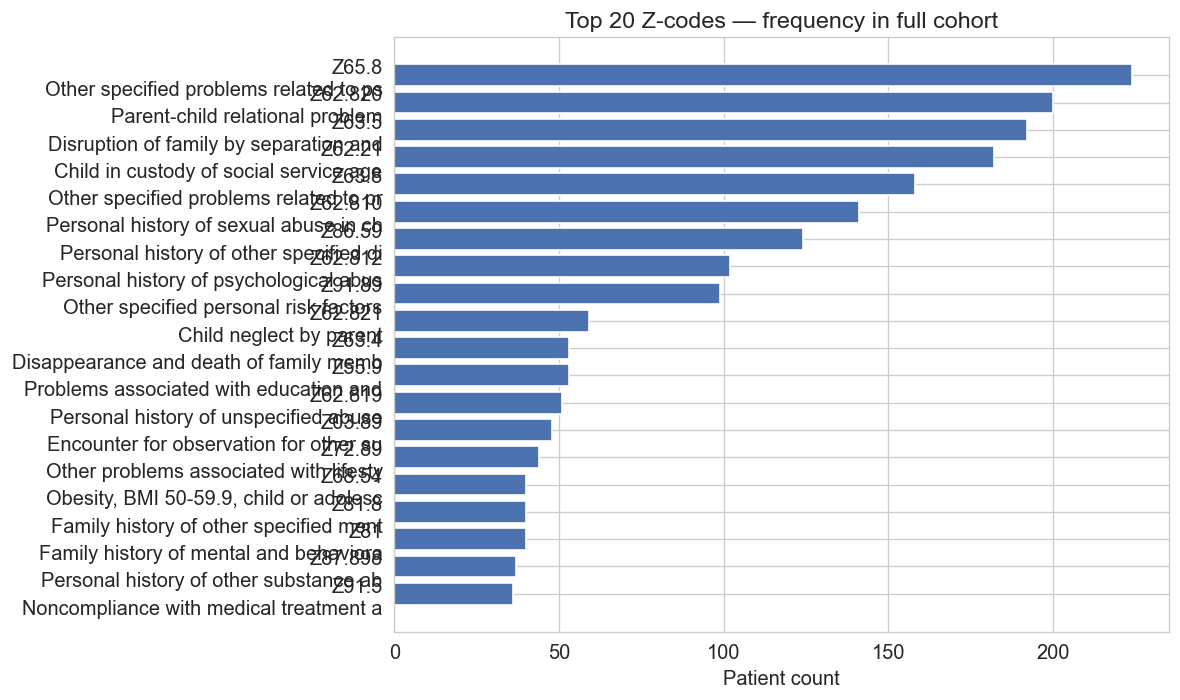

In [4]:
# ── §0Z: Z-code feature engineering & covariance with ACE / trauma ──────────────
# has_z_code = any Z-chapter ICD code in VisitDiags, ChronicDiags, or NonSuicidialDiags.
# Z-codes capture social determinants of health, adverse circumstances, and administrative
# history (e.g., Z62 problems with upbringing, Z60 social environment, Z63 family problems).
# They are NOT part of the DSM-5 category flags (those use F-codes), so they represent
# an independent social-risk dimension.
_allcodes_z = (df['VisitDiags'].fillna('') + ',' +
               df['ChronicDiags'].fillna('') + ',' +
               df['NonSuicidialDiags'].fillna('')).str.upper()
df['has_z_code'] = _allcodes_z.apply(lambda s: any(t.strip().startswith('Z') for t in s.split(',') if t.strip())).astype(int)
print(f'has_z_code prevalence: {df.has_z_code.mean()*100:.1f}% (n={df.has_z_code.sum()})')

# ── Cross-tab has_z_code × has_trauma ────────────────────────────────────────────
from scipy.stats import spearmanr
ct_zt = pd.crosstab(df['has_z_code'], df['has_trauma'])
N_both = int(ct_zt.loc[1, 1]) if (1 in ct_zt.index and 1 in ct_zt.columns) else 0
N_z_only = int(ct_zt.loc[1, 0]) if (1 in ct_zt.index and 0 in ct_zt.columns) else 0
N_tr_only = int(ct_zt.loc[0, 1]) if (0 in ct_zt.index and 1 in ct_zt.columns) else 0
N_neither = int(ct_zt.loc[0, 0]) if (0 in ct_zt.index and 0 in ct_zt.columns) else 0
# Phi coefficient for 2x2 table
_n = len(df)
phi_zt = (N_both * N_neither - N_z_only * N_tr_only) / (
    ((N_both + N_z_only) * (N_tr_only + N_neither) *
     (N_both + N_tr_only) * (N_z_only + N_neither)) ** 0.5
) if all(x > 0 for x in [N_both + N_z_only, N_tr_only + N_neither, N_both + N_tr_only, N_z_only + N_neither]) else float('nan')

print(f'\nZ-code × Trauma cross-tab:')
print(f'  Z+Trauma:  {N_both}   Z only:    {N_z_only}')
print(f'  Trauma only: {N_tr_only}   Neither: {N_neither}')
print(f'  Phi(has_z_code, has_trauma) = {phi_zt:.3f}')
print()

# ── Spearman correlations with ace_score ─────────────────────────────────────────
valid_ace = df.dropna(subset=['ace_score'])
rho_ace_z, p_ace_z = spearmanr(valid_ace['ace_score'], valid_ace['has_z_code'])
rho_ace_tr, p_ace_tr = spearmanr(valid_ace['ace_score'], valid_ace['has_trauma'])
rho_z_tr, p_z_tr = spearmanr(df['has_z_code'], df['has_trauma'])

print(f'Spearman correlations (n={len(valid_ace)} for ACE-based):')
print(f'  rho(ace_score, has_z_code)  = {rho_ace_z:.3f}  (p={pstr(p_ace_z)})')
print(f'  rho(ace_score, has_trauma)  = {rho_ace_tr:.3f}  (p={pstr(p_ace_tr)})')
print(f'  rho(has_z_code, has_trauma) = {rho_z_tr:.3f}  (p={pstr(p_z_tr)}) (n={len(df)})')
print()

# ── Interpretation ───────────────────────────────────────────────────────────────
if abs(rho_ace_z) > 0.40:
    print('INTERPRETATION: rho(ace_score, has_z_code) > 0.40.')
    print('  Z-codes partially capture ACE burden. Report in poster as:')
    print("  'Z-code social risk partially overlaps with ACE burden; not fully independent.'")
else:
    print('INTERPRETATION: rho(ace_score, has_z_code) <= 0.40.')
    print('  Z-code is a DISTINCT social-risk signal, independent of ACE score.')
    print("  Safe to report as: 'Z-code presence (any Z-chapter social/administrative code)")
    print("   represents a distinct social-risk dimension, not a proxy for ACE burden.'")

# ── Top Z-codes by frequency ──────────────────────────────────────────────────────
_zref = pd.read_csv('data/ICD10_to_DSM5_Complete_Reference.csv')
_zdesc = dict(zip(_zref['ICD_Code'], _zref['Description']))
from collections import Counter
_zcodes = Counter()
for s in _allcodes_z:
    for t in s.split(','):
        t = t.strip()
        if t.startswith('Z') and t: _zcodes[t] += 1
tc = pd.DataFrame([{'code': c, 'n': n} for c, n in _zcodes.most_common(20)])
tc['description'] = tc['code'].map(lambda c: _zdesc.get(c, _zdesc.get(c.replace('.',''), ''))[:45] if c else '')
tc['readmit_pct'] = tc['code'].map(lambda c: round(
    df[_allcodes_z.str.contains(c, regex=False)]['readmitted'].mean() * 100, 1))

def _zlbl(code):
    desc = _zdesc.get(code) or _zdesc.get(code.replace('.', ''))
    if not desc and '.' not in code and len(code) > 3:
        desc = _zdesc.get(code[:3] + '.' + code[3:])
    return f"{code}\n{desc[:38]}" if desc else code

tc['code_label'] = tc['code'].apply(_zlbl)
print('\nTop Z-codes by frequency:')
print(tc[['code', 'n', 'readmit_pct', 'description']].to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(tc['code_label'][::-1], tc['n'][::-1], color=BLUE)
ax.set_xlabel('Patient count'); ax.set_title('Top 20 Z-codes — frequency in full cohort')
plt.tight_layout(); plt.savefig('figures/Z01_zcodes_frequency.png', dpi=150); plt.show()
tc.to_csv('figures/Z01_zcode_covariance.csv', index=False)


## §0Z follow-up — Joint Z-prefix OR model and within-prefix Z-code drilldowns

This follow-up separates two questions:

1. **Broad Z-prefix groups** (3-character Z prefixes; n≥15) are modeled together in one adjusted logistic model, so their odds ratios are mutually adjusted and comparable.
2. **Individual Z codes within each prefix** are shown descriptively (n≥10) to identify which codes drive broad-prefix patterns. Single-code adjusted ORs are exploratory only (n≥30 with adequate event cells) and are not mutually adjusted across all individual codes.



§0Z joint adjusted Z-prefix model
Eligible prefixes (n>=15): Z00, Z02, Z03, Z13, Z55, Z59, Z62, Z63, Z65, Z68, Z71, Z72, Z78, Z79, Z81, Z82, Z83, Z86, Z87, Z91, Z97, Z98
Formula excludes global has_z_code: True
prefix                                                          description   n  events  readmission_rate    OR  ci_low  ci_high     p     q status
   Z00                                                                       59       7             0.119 1.050   0.430    2.566 0.914 0.925    fit
   Z02                                                                       15       2             0.133 1.445   0.304    6.866 0.643 0.893    fit
   Z03                                                                       47       2             0.043 0.432   0.099    1.893 0.266 0.850    fit
   Z13                                                                       21       3             0.143 1.164   0.315    4.299 0.820 0.925    fit
   Z55                           Problems relate

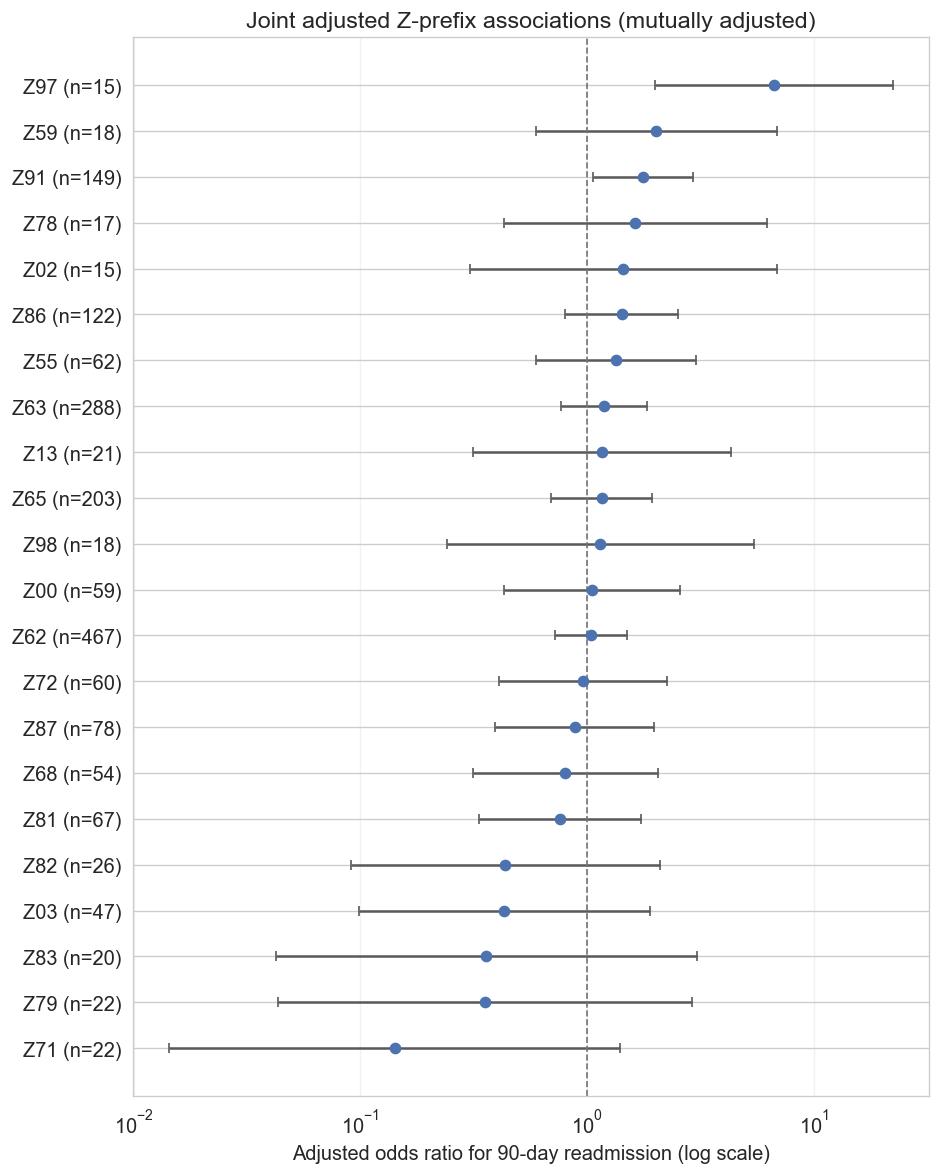


§0Z within-prefix individual Z-code drilldown
Interpretation note: prefix ORs in Z02 are mutually adjusted and comparable within the joint model;
individual-code drilldowns in Z03 are for nuance within broad Z-prefix groups. Any individual-code OR
is exploratory and adjusted one code at a time, not mutually adjusted across all individual Z codes.
parent_prefix    code                                                              description   n  events  readmission_rate  prefix_readmission_rate    OR  ci_low  ci_high     p     q         status                                      skip_reason
          Z00 Z00.129                   Encounter for screening for other developmental delays  27       4             0.148                    0.119   NaN     NaN      NaN   NaN   NaN skipped_sparse                      n<30; descriptive rate only
          Z00 Z00.121   Encounter for screening for developmental delays (performance testing)  17       3             0.176                    0.119   

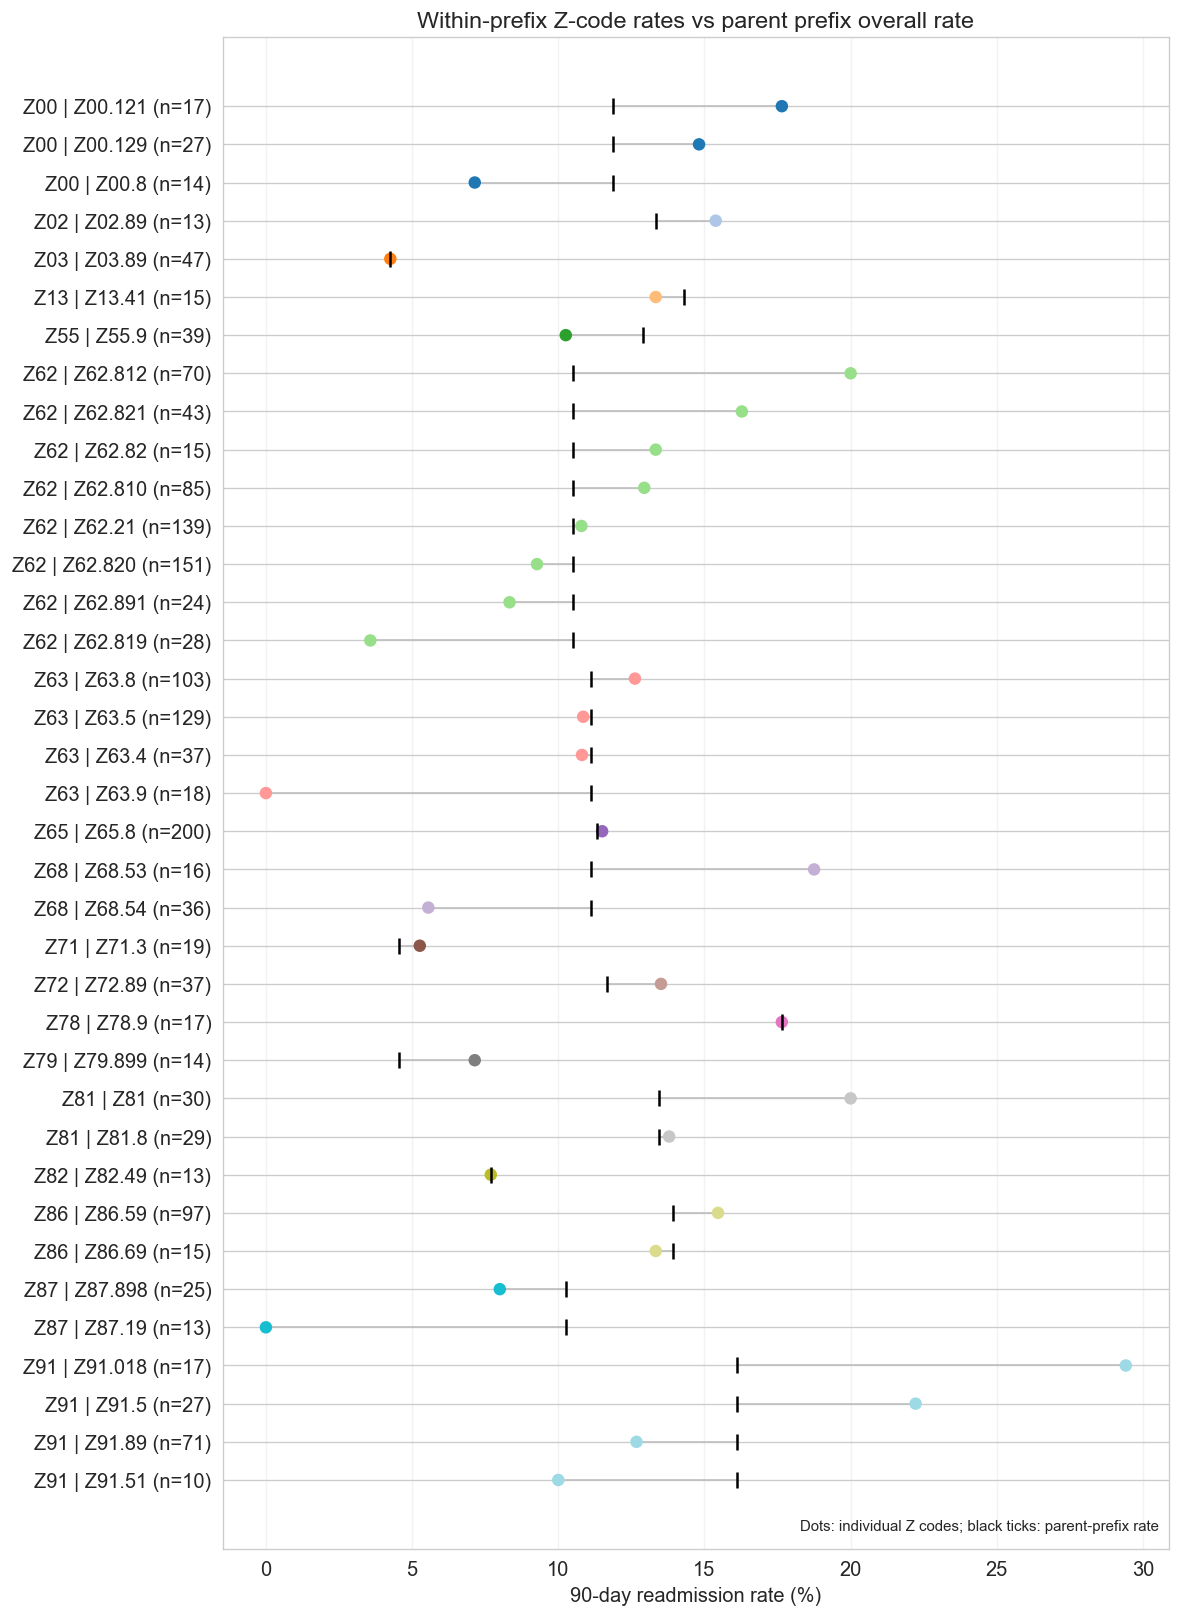

In [5]:
# ── §0Z follow-up: joint Z-prefix model + within-prefix Z-code drilldowns ─────────
# Primary model: readmitted ~ base_covariates + all eligible 3-character Z-prefix flags.
# Deliberately excludes global has_z_code to avoid collinearity with the prefix flags.
# Individual-code ORs are exploratory: each code gets its own adjusted model and codes are
# not mutually adjusted against all other individual Z codes.

from collections import defaultdict
import re

# Base covariates match the main adjusted readmission model, minus global has_z_code.
Z_BASE_COVARIATES = [
    'age', 'gender_male', 'insurance_public', 'had_restraints', 'csrss_any', 'los_days',
    'n_dsm5_categories', 'has_depression', 'has_suicidal_ideation', 'has_trauma',
    'has_adhd', 'has_nssi', 'has_psychotic', 'has_bipolar', 'has_conduct',
    'has_medical_comorbidity'
]
_z_base_formula = ' + '.join(Z_BASE_COVARIATES)

_Z_PREFIX_DESCRIPTIONS = {
    'Z55': 'Problems related to education and literacy',
    'Z56': 'Problems related to employment and unemployment',
    'Z59': 'Problems related to housing and economic circumstances',
    'Z60': 'Problems related to social environment',
    'Z62': 'Problems related to upbringing',
    'Z63': 'Other problems related to primary support group/family circumstances',
    'Z64': 'Problems related to certain psychosocial circumstances',
    'Z65': 'Problems related to other psychosocial circumstances',
    'Z72': 'Problems related to lifestyle',
    'Z73': 'Problems related to life-management difficulty',
    'Z81': 'Family history of mental and behavioral disorders',
    'Z86': 'Personal history of certain other diseases',
    'Z87': 'Personal history of other diseases and conditions',
    'Z91': 'Personal risk factors, not elsewhere classified',
}

def _normal_icd_token(token):
    token = str(token).strip().upper()
    token = re.sub(r'\s+', '', token)
    return token

def _patient_zcode_sets(row):
    vals = []
    for col in ['VisitDiags', 'ChronicDiags', 'NonSuicidialDiags']:
        v = row.get(col, '')
        if pd.notna(v) and str(v).strip():
            vals.extend(str(v).split(','))
    codes = sorted({c for c in (_normal_icd_token(x) for x in vals) if c.startswith('Z')})
    return codes

_z_code_sets = df.apply(_patient_zcode_sets, axis=1)
_z_prefix_sets = _z_code_sets.apply(lambda codes: sorted({c[:3] for c in codes if len(c) >= 3}))

_zref = pd.read_csv('data/ICD10_to_DSM5_Complete_Reference.csv')
_zref['ICD_Code_norm'] = _zref['ICD_Code'].astype(str).str.upper().str.replace(' ', '', regex=False)
_zdesc = dict(zip(_zref['ICD_Code_norm'], _zref['Description'].fillna('')))

def _desc_for_code(code):
    code = _normal_icd_token(code)
    candidates = [code, code.replace('.', '')]
    if '.' not in code and len(code) > 3:
        candidates.append(code[:3] + '.' + code[3:])
    for cand in candidates:
        desc = _zdesc.get(cand)
        if desc:
            return desc
    return ''

def _zflag_from_sets(series_of_sets, value):
    return series_of_sets.apply(lambda xs: int(value in xs))

def _safe_fdr(pvals):
    p = pd.Series(pvals, dtype='float64')
    q = pd.Series(np.nan, index=p.index, dtype='float64')
    ok = p.notna()
    if ok.any():
        q.loc[ok] = multipletests(p.loc[ok], method='fdr_bh')[1]
    return q

# ── Prefix-level mutually adjusted model ─────────────────────────────────────
_prefix_counts = Counter(p for prefixes in _z_prefix_sets for p in prefixes)
eligible_prefixes = sorted([p for p, n in _prefix_counts.items() if n >= 15])
for prefix in eligible_prefixes:
    df[f'zprefix_{prefix}'] = _zflag_from_sets(_z_prefix_sets, prefix)

prefix_rows = []
if len(eligible_prefixes) >= 2:
    zprefix_terms = [f'zprefix_{p}' for p in eligible_prefixes]
    zprefix_formula = 'readmitted ~ ' + _z_base_formula + ' + ' + ' + '.join(zprefix_terms)
    if 'has_z_code' in zprefix_formula:
        raise RuntimeError('Joint Z-prefix formula unexpectedly includes has_z_code')
    try:
        zprefix_model = smf.logit(zprefix_formula, data=df).fit(disp=0, maxiter=500)
        ci = zprefix_model.conf_int()
        for prefix in eligible_prefixes:
            term = f'zprefix_{prefix}'
            flag = df[term].astype(int)
            n = int(flag.sum())
            events = int(df.loc[flag == 1, 'readmitted'].sum())
            prefix_rows.append({
                'row_type': 'prefix',
                'prefix': prefix,
                'code': prefix,
                'parent_prefix': prefix,
                'description': _Z_PREFIX_DESCRIPTIONS.get(prefix, ''),
                'n': n,
                'events': events,
                'readmission_rate': events / n if n else np.nan,
                'OR': float(np.exp(zprefix_model.params[term])),
                'ci_low': float(np.exp(ci.loc[term, 0])),
                'ci_high': float(np.exp(ci.loc[term, 1])),
                'p': float(zprefix_model.pvalues[term]),
                'q': np.nan,
                'model_type': 'joint_prefix_adjusted',
                'status': 'fit',
                'skip_reason': '',
                'formula': zprefix_formula,
            })
    except Exception as e:
        zprefix_formula = 'readmitted ~ ' + _z_base_formula + ' + ' + ' + '.join([f'zprefix_{p}' for p in eligible_prefixes])
        for prefix in eligible_prefixes:
            flag = df[f'zprefix_{prefix}'].astype(int)
            n = int(flag.sum())
            events = int(df.loc[flag == 1, 'readmitted'].sum())
            prefix_rows.append({
                'row_type': 'prefix', 'prefix': prefix, 'code': prefix, 'parent_prefix': prefix,
                'description': _Z_PREFIX_DESCRIPTIONS.get(prefix, ''), 'n': n, 'events': events,
                'readmission_rate': events / n if n else np.nan, 'OR': np.nan, 'ci_low': np.nan,
                'ci_high': np.nan, 'p': np.nan, 'q': np.nan, 'model_type': 'joint_prefix_adjusted',
                'status': 'failed', 'skip_reason': type(e).__name__ + ': ' + str(e),
                'formula': zprefix_formula,
            })
else:
    zprefix_formula = 'not fit: fewer than two eligible prefixes with n>=15'
    for prefix in eligible_prefixes:
        flag = df[f'zprefix_{prefix}'].astype(int)
        n = int(flag.sum())
        events = int(df.loc[flag == 1, 'readmitted'].sum())
        prefix_rows.append({
            'row_type': 'prefix', 'prefix': prefix, 'code': prefix, 'parent_prefix': prefix,
            'description': _Z_PREFIX_DESCRIPTIONS.get(prefix, ''), 'n': n, 'events': events,
            'readmission_rate': events / n if n else np.nan, 'OR': np.nan, 'ci_low': np.nan,
            'ci_high': np.nan, 'p': np.nan, 'q': np.nan, 'model_type': 'joint_prefix_adjusted',
            'status': 'skipped', 'skip_reason': 'fewer than two eligible prefixes with n>=15',
            'formula': zprefix_formula,
        })

zprefix_joint = pd.DataFrame(prefix_rows)
if not zprefix_joint.empty:
    zprefix_joint['q'] = _safe_fdr(zprefix_joint['p'])
zprefix_joint.to_csv('figures/Z02_zprefix_joint_or.csv', index=False)

print('\n§0Z joint adjusted Z-prefix model')
print(f'Eligible prefixes (n>=15): {", ".join(eligible_prefixes) if eligible_prefixes else "none"}')
print('Formula excludes global has_z_code:', 'has_z_code' not in zprefix_formula)
if not zprefix_joint.empty:
    display_cols = ['prefix', 'description', 'n', 'events', 'readmission_rate', 'OR', 'ci_low', 'ci_high', 'p', 'q', 'status']
    print(zprefix_joint[display_cols].sort_values('prefix').round(3).to_string(index=False))
else:
    print('No eligible Z-prefixes to model.')

# Forest plot for joint prefix adjusted ORs.
plot_joint = zprefix_joint[(zprefix_joint['status'] == 'fit') & zprefix_joint['OR'].notna()].copy()
if not plot_joint.empty:
    plot_joint = plot_joint.sort_values('OR')
    labels = plot_joint.apply(lambda r: f"{r['prefix']} (n={int(r['n'])})", axis=1)
    y = np.arange(len(plot_joint))
    fig, ax = plt.subplots(figsize=(8, max(4, 0.38 * len(plot_joint) + 1.6)))
    ax.errorbar(
        plot_joint['OR'], y,
        xerr=[plot_joint['OR'] - plot_joint['ci_low'], plot_joint['ci_high'] - plot_joint['OR']],
        fmt='o', color=BLUE, ecolor='0.35', capsize=3
    )
    ax.axvline(1, color='0.45', linestyle='--', linewidth=1)
    ax.set_xscale('log')
    ax.set_yticks(y); ax.set_yticklabels(labels)
    ax.set_xlabel('Adjusted odds ratio for 90-day readmission (log scale)')
    ax.set_title('Joint adjusted Z-prefix associations (mutually adjusted)')
    ax.grid(True, axis='x', alpha=0.25)
    plt.tight_layout(); plt.savefig('figures/Z02_zprefix_joint_or.png', dpi=200); plt.show()
else:
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.axis('off')
    ax.text(0.02, 0.6, 'No Z-prefix ORs were estimable; see CSV status/skip_reason.', fontsize=12)
    plt.tight_layout(); plt.savefig('figures/Z02_zprefix_joint_or.png', dpi=200); plt.show()

# ── Individual Z-code drilldowns nested under eligible parent prefixes ───────
_code_counts = Counter(c for codes in _z_code_sets for c in codes)
code_rows = []
for prefix in eligible_prefixes:
    pflag = df[f'zprefix_{prefix}'].astype(int)
    pn = int(pflag.sum())
    pevents = int(df.loc[pflag == 1, 'readmitted'].sum())
    prate = pevents / pn if pn else np.nan
    code_rows.append({
        'row_type': 'prefix_overall',
        'prefix': prefix,
        'code': prefix,
        'parent_prefix': prefix,
        'description': _Z_PREFIX_DESCRIPTIONS.get(prefix, ''),
        'n': pn,
        'events': pevents,
        'readmission_rate': prate,
        'prefix_n': pn,
        'prefix_events': pevents,
        'prefix_readmission_rate': prate,
        'OR': np.nan,
        'ci_low': np.nan,
        'ci_high': np.nan,
        'p': np.nan,
        'q': np.nan,
        'model_type': 'prefix_descriptive_rate',
        'status': 'descriptive_only',
        'skip_reason': 'prefix overall reference row; see Z02 for mutually adjusted prefix OR',
        'formula': '',
    })

    prefix_codes = sorted([c for c, n in _code_counts.items() if c.startswith(prefix) and n >= 10],
                          key=lambda c: (-_code_counts[c], c))
    for code_value in prefix_codes:
        flag_name = 'zcode_' + re.sub(r'[^A-Z0-9]+', '_', code_value)
        df[flag_name] = _zflag_from_sets(_z_code_sets, code_value)
        cflag = df[flag_name].astype(int)
        n = int(cflag.sum())
        events = int(df.loc[cflag == 1, 'readmitted'].sum())
        nonevents = int(n - events)
        unexp_events = int(df.loc[cflag == 0, 'readmitted'].sum())
        unexp_nonevents = int((cflag == 0).sum() - unexp_events)
        row = {
            'row_type': 'individual_code',
            'prefix': prefix,
            'code': code_value,
            'parent_prefix': prefix,
            'description': _desc_for_code(code_value),
            'n': n,
            'events': events,
            'readmission_rate': events / n if n else np.nan,
            'prefix_n': pn,
            'prefix_events': pevents,
            'prefix_readmission_rate': prate,
            'OR': np.nan,
            'ci_low': np.nan,
            'ci_high': np.nan,
            'p': np.nan,
            'q': np.nan,
            'model_type': 'exploratory_single_code_adjusted',
            'status': 'skipped',
            'skip_reason': '',
            'formula': '',
        }
        if n < 30:
            row['model_type'] = 'descriptive_only'
            row['status'] = 'skipped_sparse'
            row['skip_reason'] = 'n<30; descriptive rate only'
        elif min(events, nonevents, unexp_events, unexp_nonevents) < 5:
            row['status'] = 'skipped_sparse'
            row['skip_reason'] = 'minimum 2x2 cell count <5; descriptive rate only'
        else:
            single_formula = 'readmitted ~ ' + _z_base_formula + ' + ' + flag_name
            try:
                smod = smf.logit(single_formula, data=df).fit(disp=0, maxiter=500)
                sci = smod.conf_int()
                row.update({
                    'OR': float(np.exp(smod.params[flag_name])),
                    'ci_low': float(np.exp(sci.loc[flag_name, 0])),
                    'ci_high': float(np.exp(sci.loc[flag_name, 1])),
                    'p': float(smod.pvalues[flag_name]),
                    'status': 'fit',
                    'skip_reason': '',
                    'formula': single_formula,
                })
            except Exception as e:
                row['status'] = 'failed'
                row['skip_reason'] = type(e).__name__ + ': ' + str(e)
                row['formula'] = single_formula
        code_rows.append(row)

zcode_drilldown = pd.DataFrame(code_rows)
if not zcode_drilldown.empty:
    code_fit_mask = (zcode_drilldown['row_type'].eq('individual_code') &
                     zcode_drilldown['status'].eq('fit') &
                     zcode_drilldown['p'].notna())
    zcode_drilldown.loc[code_fit_mask, 'q'] = _safe_fdr(zcode_drilldown.loc[code_fit_mask, 'p'])
zcode_drilldown.to_csv('figures/Z03_zcode_within_prefix_drilldown.csv', index=False)

print('\n§0Z within-prefix individual Z-code drilldown')
print('Interpretation note: prefix ORs in Z02 are mutually adjusted and comparable within the joint model;')
print('individual-code drilldowns in Z03 are for nuance within broad Z-prefix groups. Any individual-code OR')
print('is exploratory and adjusted one code at a time, not mutually adjusted across all individual Z codes.')
if not zcode_drilldown.empty:
    show_cols = ['parent_prefix', 'code', 'description', 'n', 'events', 'readmission_rate',
                 'prefix_readmission_rate', 'OR', 'ci_low', 'ci_high', 'p', 'q', 'status', 'skip_reason']
    print(zcode_drilldown[zcode_drilldown['row_type'].eq('individual_code')][show_cols].round(3).to_string(index=False))
else:
    print('No individual Z codes met n>=10 within eligible prefixes.')

# Within-prefix rate plot: individual code rates compared with each parent prefix overall rate.
plot_codes = zcode_drilldown[zcode_drilldown['row_type'].eq('individual_code')].copy()
if not plot_codes.empty:
    plot_codes = plot_codes.sort_values(['parent_prefix', 'readmission_rate', 'n'], ascending=[True, False, False])
    plot_codes['label'] = plot_codes.apply(
        lambda r: f"{r['parent_prefix']} | {r['code']} (n={int(r['n'])})", axis=1
    )
    y = np.arange(len(plot_codes))
    fig_h = min(16, max(5, 0.32 * len(plot_codes) + 1.8))
    fig, ax = plt.subplots(figsize=(10, fig_h))
    colors = plot_codes['parent_prefix'].astype('category').cat.codes
    ax.scatter(plot_codes['readmission_rate'] * 100, y, c=colors, cmap='tab20', s=42, zorder=3)
    for yi, (_, r) in zip(y, plot_codes.iterrows()):
        ax.plot([r['prefix_readmission_rate'] * 100, r['readmission_rate'] * 100], [yi, yi], color='0.75', linewidth=1, zorder=1)
        ax.scatter([r['prefix_readmission_rate'] * 100], [yi], marker='|', color='black', s=90, zorder=4)
    ax.set_yticks(y); ax.set_yticklabels(plot_codes['label'])
    ax.invert_yaxis()
    ax.set_xlabel('90-day readmission rate (%)')
    ax.set_title('Within-prefix Z-code rates vs parent prefix overall rate')
    ax.text(0.99, 0.01, 'Dots: individual Z codes; black ticks: parent-prefix rate',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=9)
    ax.grid(True, axis='x', alpha=0.25)
    plt.tight_layout(); plt.savefig('figures/Z03_zcode_within_prefix_drilldown.png', dpi=200); plt.show()
else:
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.axis('off')
    ax.text(0.02, 0.6, 'No individual Z codes met n>=10 within eligible prefixes.', fontsize=12)
    plt.tight_layout(); plt.savefig('figures/Z03_zcode_within_prefix_drilldown.png', dpi=200); plt.show()


## §1 — Bivariate inferential analyses
Each association has a test and a figure; the diagnosis↔LOS family is FDR-corrected.

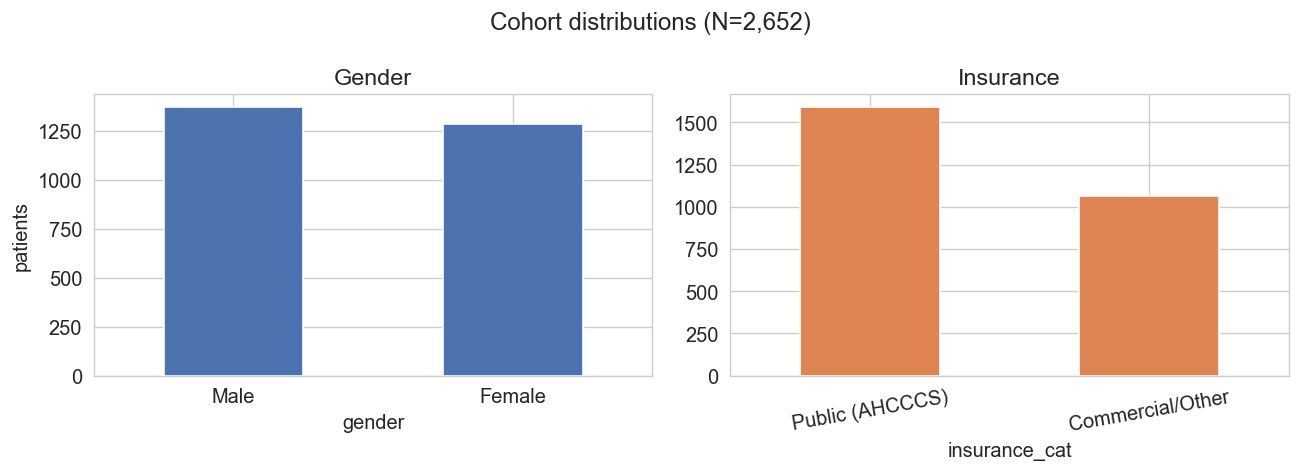

Gender: {'Male': np.int64(1369), 'Female': np.int64(1283)} | Insurance: {'Public (AHCCCS)': np.int64(1589), 'Commercial/Other': np.int64(1063)}


In [6]:
# 1. Gender & insurance distributions
fig,ax=plt.subplots(1,2,figsize=(11,4))
df['gender'].value_counts().plot.bar(ax=ax[0],color=BLUE); ax[0].set_title('Gender'); ax[0].set_ylabel('patients'); ax[0].tick_params(axis='x',rotation=0)
df['insurance_cat'].value_counts().plot.bar(ax=ax[1],color=ORANGE); ax[1].set_title('Insurance'); ax[1].tick_params(axis='x',rotation=10)
plt.suptitle('Cohort distributions (N=2,652)'); plt.tight_layout(); plt.savefig('figures/Biv_01_distributions.png'); plt.show()
print('Gender:',dict(df.gender.value_counts()),'| Insurance:',dict(df.insurance_cat.value_counts()))

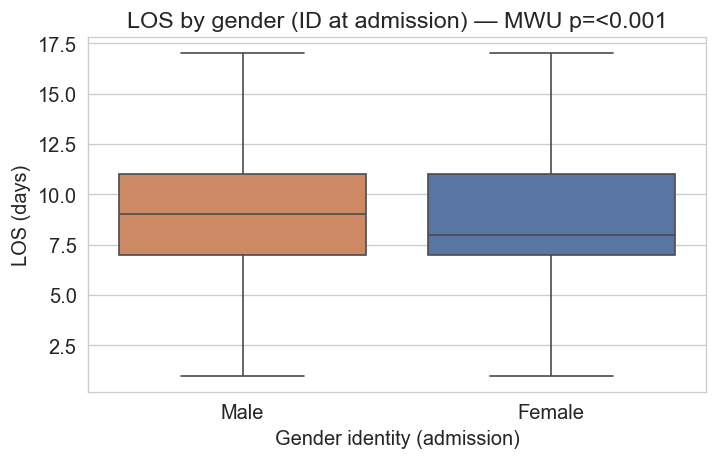

Male median LOS=9 (n=1369) vs Female=8 (n=1283); MWU p=<0.001


In [7]:
# 2. LOS by gender identity at admission (GenderCode = gender ID, not sex) — Mann-Whitney
r=mwu(df[df.gender_male==1].los_days, df[df.gender_male==0].los_days)
fig,ax=plt.subplots(figsize=(6,4)); sns.boxplot(data=df,x='gender',y='los_days',ax=ax,showfliers=False,palette=[ORANGE,BLUE])
ax.set_title(f'LOS by gender (ID at admission) — MWU p={pstr(r["p"])}'); ax.set_xlabel('Gender identity (admission)'); ax.set_ylabel('LOS (days)'); plt.tight_layout(); plt.savefig('figures/Biv_02_los_by_sex.png'); plt.show()
print(f'Male median LOS={r["med1"]:.0f} (n={r["n1"]}) vs Female={r["med2"]:.0f} (n={r["n2"]}); MWU p={pstr(r["p"])}')

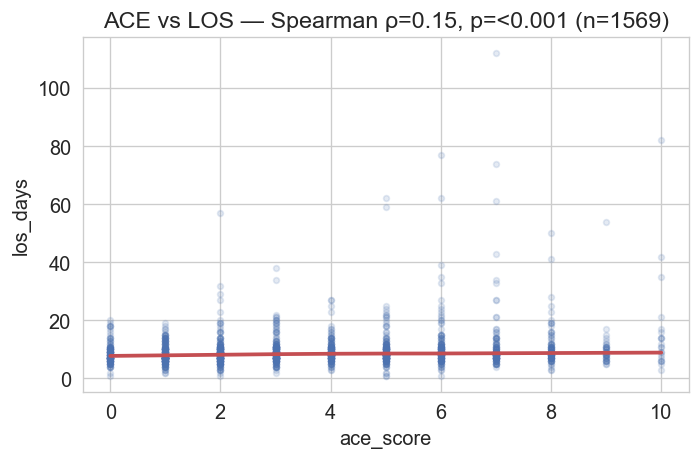

ACE~LOS Spearman rho=0.148, p=<0.001, n=1569


In [8]:
# 3. ACE vs LOS (Spearman)
r=spear(df.ace_score, df.los_days)
d=df.dropna(subset=['ace_score','los_days'])
fig,ax=plt.subplots(figsize=(6,4)); sns.regplot(data=d,x='ace_score',y='los_days',lowess=True,scatter_kws=dict(alpha=.15,s=12,color=BLUE),line_kws=dict(color=RED),ax=ax)
ax.set_title(f'ACE vs LOS — Spearman ρ={r["rho"]:.2f}, p={pstr(r["p"])} (n={r["n"]})'); plt.tight_layout(); plt.savefig('figures/Biv_03_ace_los.png'); plt.show()
print(f'ACE~LOS Spearman rho={r["rho"]:.3f}, p={pstr(r["p"])}, n={r["n"]}')

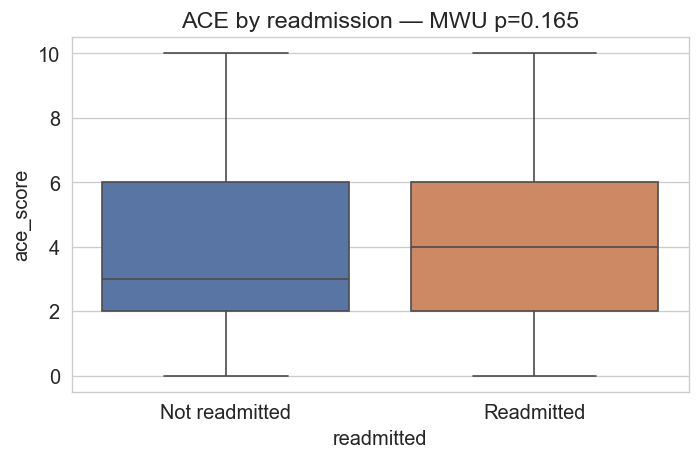

ACE readmitted median=4.0 vs not=3.0; MWU p=0.165


In [9]:
# 4. ACE in readmitted vs not (Mann-Whitney)
r=mwu(df[df.readmitted==1].ace_score, df[df.readmitted==0].ace_score)
fig,ax=plt.subplots(figsize=(6,4)); sns.boxplot(data=df,x='readmitted',y='ace_score',ax=ax,showfliers=False,palette=[BLUE,ORANGE])
ax.set_xticklabels(['Not readmitted','Readmitted']); ax.set_title(f'ACE by readmission — MWU p={pstr(r["p"])}'); plt.tight_layout(); plt.savefig('figures/Biv_04_ace_readmit.png'); plt.show()
print(f'ACE readmitted median={r["med1"]:.1f} vs not={r["med2"]:.1f}; MWU p={pstr(r["p"])}')

Suicidality measured two ways (readmission) — the ICD code is the original analysis's operationalization:
                        measure  prevalence_%  readmit_with_%  readmit_without_%  univariate_OR      p
Suicidal ideation (ICD R45.851)          50.8            11.4                7.1           1.67 <0.001
                Any C-SSRS flag          32.4             9.4                9.2           1.03  0.861


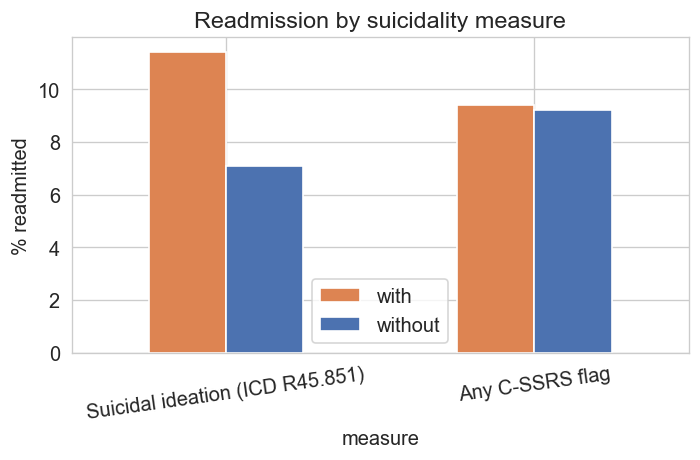

In [10]:
# 4b. Suicidality — ICD code (R45.851 ideation) vs C-SSRS flag: DIFFERENT constructs, opposite signals
si=odds_ratio_2x2(df['has_suicidal_ideation'],'readmitted'); cf=odds_ratio_2x2(df['csrss_any'],'readmitted')
rates=pd.DataFrame({
 'measure':['Suicidal ideation (ICD R45.851)','Any C-SSRS flag'],
 'prevalence_%':[round(df.has_suicidal_ideation.mean()*100,1),round(df.csrss_any.mean()*100,1)],
 'readmit_with_%':[round(df[df.has_suicidal_ideation==1].readmitted.mean()*100,1),round(df[df.csrss_any==1].readmitted.mean()*100,1)],
 'readmit_without_%':[round(df[df.has_suicidal_ideation==0].readmitted.mean()*100,1),round(df[df.csrss_any==0].readmitted.mean()*100,1)],
 'univariate_OR':[round(si[0],2),round(cf[0],2)],'p':[pstr(si[1]),pstr(cf[1])]})
rates.to_csv('figures/Biv_04b_suicidality_measures.csv',index=False)
print('Suicidality measured two ways (readmission) — the ICD code is the original analysis\'s operationalization:')
print(rates.to_string(index=False))
fig,ax=plt.subplots(figsize=(6,4))
rates.set_index('measure')[['readmit_with_%','readmit_without_%']].plot.bar(ax=ax,color=[ORANGE,BLUE])
ax.set_ylabel('% readmitted'); ax.set_title('Readmission by suicidality measure'); ax.tick_params(axis='x',rotation=8); ax.legend(['with','without'])
plt.tight_layout(); plt.savefig('figures/Biv_04b_suicidality_measures.png'); plt.show()

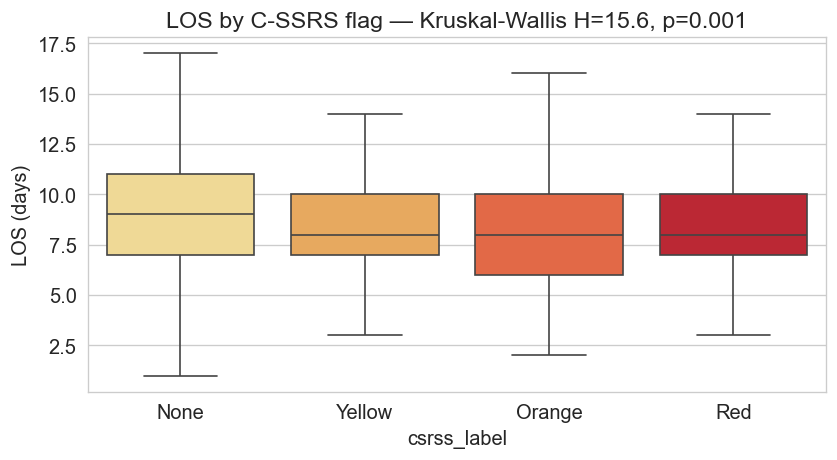

Median LOS by C-SSRS: {0: np.float64(9.0), 1: np.float64(8.0), 2: np.float64(8.0), 3: np.float64(8.0)} | KW p= 0.001


In [11]:
# 5 & 11. LOS by C-SSRS level (Kruskal-Wallis)
r=kruskal([df[df.csrss_level==l].los_days for l in [0,1,2,3]])
fig,ax=plt.subplots(figsize=(7,4)); sns.boxplot(data=df,x='csrss_label',y='los_days',order=['None','Yellow','Orange','Red'],ax=ax,showfliers=False,palette='YlOrRd')
ax.set_title(f'LOS by C-SSRS flag — Kruskal-Wallis H={r["H"]:.1f}, p={pstr(r["p"])}'); ax.set_ylabel('LOS (days)'); plt.tight_layout(); plt.savefig('figures/Biv_05_los_cssrs.png'); plt.show()
print('Median LOS by C-SSRS:',{df.csrss_label.map({0:"None"}).iloc[0] if False else l:round(df[df.csrss_level==l].los_days.median(),1) for l in [0,1,2,3]},'| KW p=',pstr(r['p']))

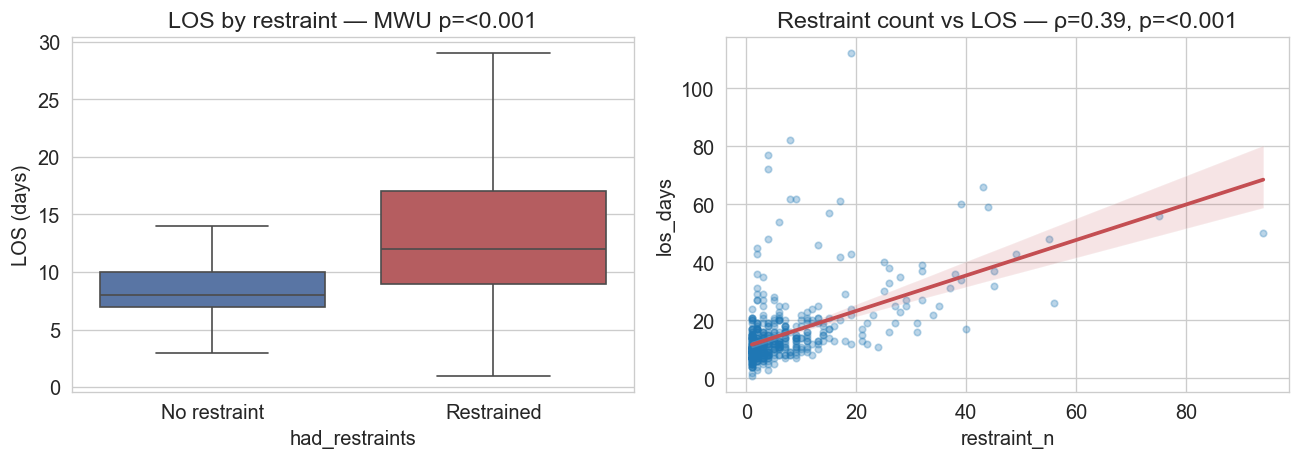

LOS restrained median=12 vs not=8, MWU p=<0.001; Spearman(count,LOS) rho=0.386, p=<0.001


In [12]:
# 6. Restraint vs LOS (Mann-Whitney + Spearman on count)
r1=mwu(df[df.had_restraints==1].los_days, df[df.had_restraints==0].los_days)
r2=spear(df.restraint_n, df.los_days)
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.boxplot(data=df,x='had_restraints',y='los_days',ax=ax[0],showfliers=False,palette=[BLUE,RED]); ax[0].set_xticklabels(['No restraint','Restrained']); ax[0].set_title(f'LOS by restraint — MWU p={pstr(r1["p"])}'); ax[0].set_ylabel('LOS (days)')
d=df[df.restraint_n>0]; sns.regplot(data=d,x='restraint_n',y='los_days',scatter_kws=dict(alpha=.3,s=15),line_kws=dict(color=RED),ax=ax[1]); ax[1].set_title(f'Restraint count vs LOS — ρ={r2["rho"]:.2f}, p={pstr(r2["p"])}')
plt.tight_layout(); plt.savefig('figures/Biv_06_restraint_los.png'); plt.show()
print(f'LOS restrained median={r1["med1"]:.0f} vs not={r1["med2"]:.0f}, MWU p={pstr(r1["p"])}; Spearman(count,LOS) rho={r2["rho"]:.3f}, p={pstr(r2["p"])}')

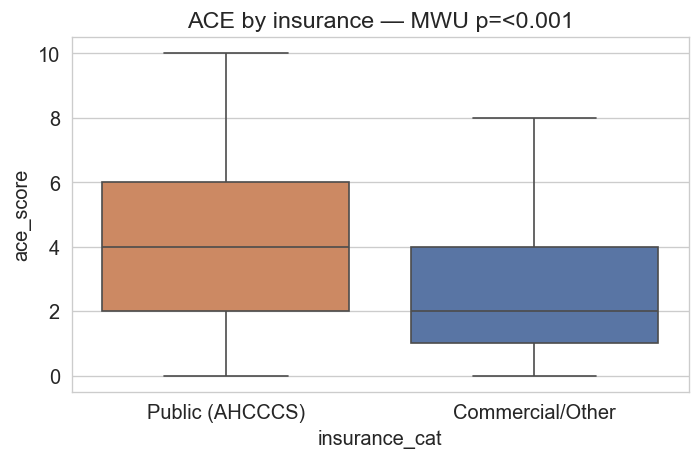

ACE public median=4.0 (n=960) vs commercial/other=2.0 (n=609); MWU p=<0.001


In [13]:
# 7. ACE by insurance (Mann-Whitney)
r=mwu(df[df.insurance_public==1].ace_score, df[df.insurance_public==0].ace_score)
fig,ax=plt.subplots(figsize=(6,4)); sns.boxplot(data=df,x='insurance_cat',y='ace_score',ax=ax,showfliers=False,palette=[ORANGE,BLUE]); ax.set_title(f'ACE by insurance — MWU p={pstr(r["p"])}'); plt.tight_layout(); plt.savefig('figures/Biv_07_ace_insurance.png'); plt.show()
print(f'ACE public median={r["med1"]:.1f} (n={r["n1"]}) vs commercial/other={r["med2"]:.1f} (n={r["n2"]}); MWU p={pstr(r["p"])}')

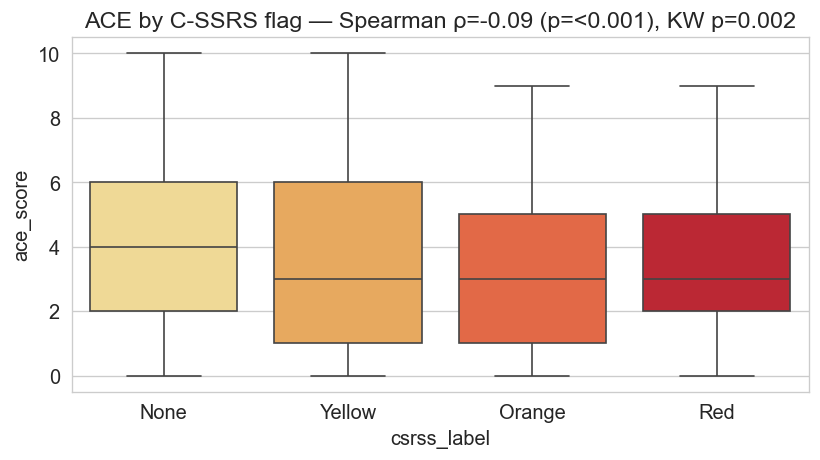

ACE~CSSRS Spearman rho=-0.091 p=<0.001; Kruskal p=0.002


In [14]:
# 8. ACE vs C-SSRS level (Spearman + Kruskal)
rs=spear(df.ace_score, df.csrss_level); rk=kruskal([df[df.csrss_level==l].ace_score for l in [0,1,2,3]])
fig,ax=plt.subplots(figsize=(7,4)); sns.boxplot(data=df,x='csrss_label',y='ace_score',order=['None','Yellow','Orange','Red'],ax=ax,showfliers=False,palette='YlOrRd'); ax.set_title(f'ACE by C-SSRS flag — Spearman ρ={rs["rho"]:.2f} (p={pstr(rs["p"])}), KW p={pstr(rk["p"])}'); plt.tight_layout(); plt.savefig('figures/Biv_08_ace_cssrs.png'); plt.show()
print(f'ACE~CSSRS Spearman rho={rs["rho"]:.3f} p={pstr(rs["p"])}; Kruskal p={pstr(rk["p"])}')

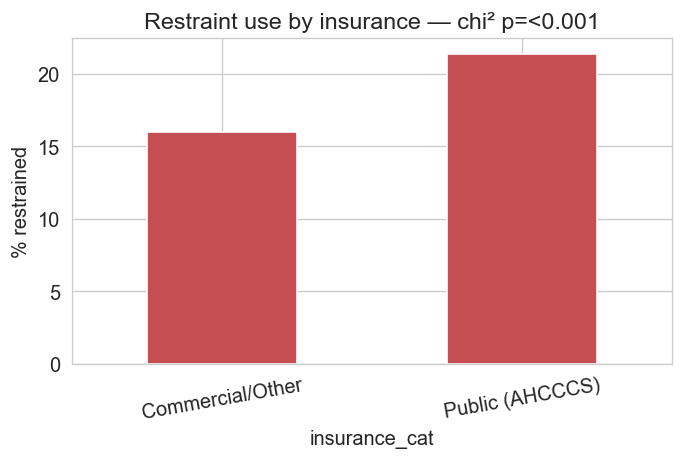

Restraint×insurance chi² p=<0.001; % restrained: {'Commercial/Other': np.float64(16.0), 'Public (AHCCCS)': np.float64(21.4)}


In [15]:
# 9. Restraint x insurance (chi-square)
r=chi2(df.had_restraints, df.insurance_cat)
ct=pd.crosstab(df.insurance_cat, df.had_restraints, normalize='index')*100
fig,ax=plt.subplots(figsize=(6,4)); ct[1].plot.bar(ax=ax,color=RED); ax.set_ylabel('% restrained'); ax.set_title(f'Restraint use by insurance — chi² p={pstr(r["p"])}'); ax.tick_params(axis='x',rotation=10); plt.tight_layout(); plt.savefig('figures/Biv_09_restraint_insurance.png'); plt.show()
print(f'Restraint×insurance chi² p={pstr(r["p"])}; % restrained:',dict((ct[1]).round(1)))

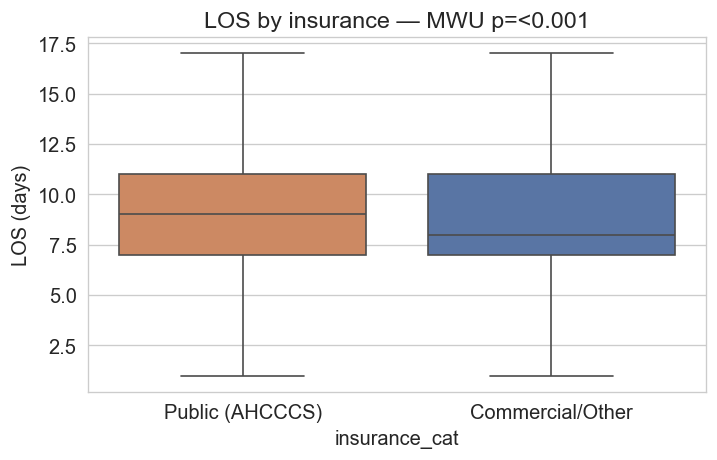

LOS public median=9 vs commercial/other=8; MWU p=<0.001


In [16]:
# 10. Insurance vs LOS (Mann-Whitney)
r=mwu(df[df.insurance_public==1].los_days, df[df.insurance_public==0].los_days)
fig,ax=plt.subplots(figsize=(6,4)); sns.boxplot(data=df,x='insurance_cat',y='los_days',ax=ax,showfliers=False,palette=[ORANGE,BLUE]); ax.set_title(f'LOS by insurance — MWU p={pstr(r["p"])}'); ax.set_ylabel('LOS (days)'); plt.tight_layout(); plt.savefig('figures/Biv_10_los_insurance.png'); plt.show()
print(f'LOS public median={r["med1"]:.0f} vs commercial/other={r["med2"]:.0f}; MWU p={pstr(r["p"])}')

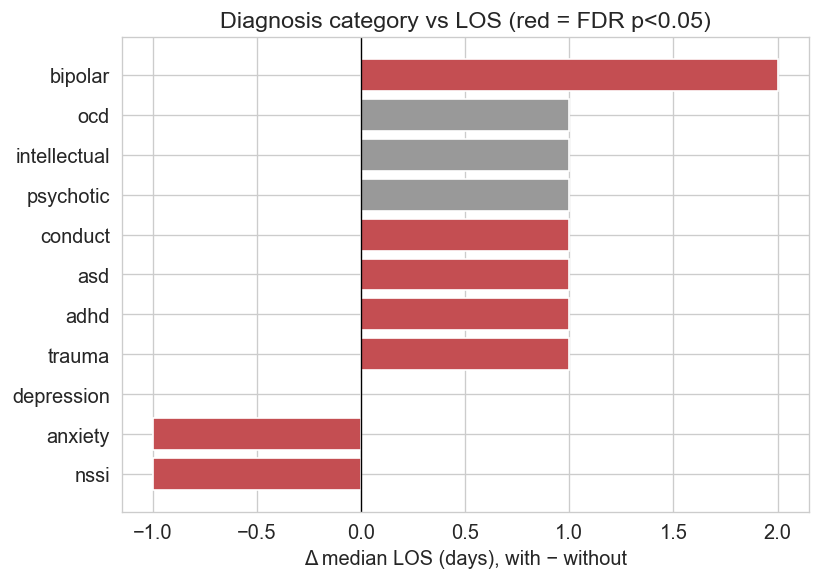

    category  n_with  delta            p        p_fdr
        nssi     966   -1.0 1.003370e-08 5.518534e-08
     anxiety    1154   -1.0 3.091773e-05 8.502375e-05
  depression    1779    0.0 9.037008e-01 9.037008e-01
      trauma    1424    1.0 4.637061e-05 1.020153e-04
        adhd    1399    1.0 1.033901e-16 1.137291e-15
         asd     513    1.0 8.624925e-08 3.162473e-07
     conduct     484    1.0 4.303870e-04 6.763225e-04
   psychotic      55    1.0 4.034341e-01 4.930861e-01
intellectual      57    1.0 1.909325e-01 2.625322e-01
         ocd     114    1.0 5.131705e-01 5.644875e-01
     bipolar     147    2.0 3.489028e-04 6.396552e-04


In [17]:
# 12. Diagnosis (DSM-5 category) vs LOS — FDR-corrected, forest of median differences
rows=[]
for f,kw in CATEGORY_FLAGS.items():
    r=mwu(df[df[f]==1].los_days, df[df[f]==0].los_days)
    rows.append(dict(category=f.replace('has_',''), n_with=r['n1'], med_with=r['med1'], med_without=r['med2'], delta=r['med1']-r['med2'], p=r['p']))
dd=pd.DataFrame(rows); dd['p_fdr']=multipletests(dd['p'],method='fdr_bh')[1]; dd=dd.sort_values('delta')
dd.to_csv('figures/Biv_12_diagnosis_los.csv', index=False)
fig,ax=plt.subplots(figsize=(7,5))
colors=[RED if (s<0.05) else '0.6' for s in dd['p_fdr']]
ax.barh(dd['category'], dd['delta'], color=colors); ax.axvline(0,color='k',lw=.8)
ax.set_xlabel('Δ median LOS (days), with − without'); ax.set_title('Diagnosis category vs LOS (red = FDR p<0.05)')
plt.tight_layout(); plt.savefig('figures/Biv_12_diagnosis_los.png'); plt.show()
print(dd[['category','n_with','delta','p','p_fdr']].to_string(index=False))

## §2 — Subgroup descriptive statistics
For each diagnosis column (**Visit**, **Chronic**, **Non-suicidal**), DSM-5 category subgroups
(n≥30) are described against four outcomes: **readmission** (rate + univariate OR), **LOS**
(median Δ), **ACE** (mean Δ), and **restraint** (rate + OR). FDR-corrected per outcome; forest
panels mark associated vs not.

In [18]:
# Build per-column DSM-5 category subgroup flags, then describe vs 4 outcomes
DIAG_COLS = {'Visit':'VisitDiags_DSM5Categories','Chronic':'ChronicDiags_DSM5Categories','NonSuicidal':'NonSuicidialDiags_DSM5Categories'}
KWS = {'NSSI':'non-suicidal self-injury','Trauma/Stressor':'trauma and stressor','ADHD':'adhd',
       'ASD':'autism spectrum','Conduct':'conduct disorder','Depressive':'depressive disorders',
       'Anxiety':'anxiety disorders','Bipolar':'bipolar','Psychotic':'psychotic'}
rows=[]
for colname, col in DIAG_COLS.items():
    if col not in df.columns: continue
    series = df[col].fillna('').str.lower()
    for label, kw in KWS.items():
        flag = series.str.contains(kw, na=False).astype(int)
        n = int(flag.sum())
        if n < 30: continue
        with_, without = df[flag==1], df[flag==0]
        rr_with = with_['readmitted'].mean()*100; rr_wo = without['readmitted'].mean()*100
        or_re,p_re = odds_ratio_2x2(flag,'readmitted')
        los = mwu(with_.los_days, without.los_days)
        ace = mwu(with_.ace_score, without.ace_score)
        or_rs,p_rs = odds_ratio_2x2(flag,'had_restraints')
        rows.append(dict(column=colname, subgroup=label, n=n,
            readmit_pct=round(rr_with,1), readmit_OR=round(or_re,2), p_readmit=p_re,
            dLOS=los['med1']-los['med2'], p_los=los['p'],
            dACE=(ace['med1']-ace['med2']), p_ace=ace['p'],
            restraint_OR=round(or_rs,2), p_restraint=p_rs))
sub=pd.DataFrame(rows)
for outcome,pcol in [('readmit','p_readmit'),('los','p_los'),('ace','p_ace'),('restraint','p_restraint')]:
    sub[f'{pcol}_fdr']=multipletests(sub[pcol].fillna(1),method='fdr_bh')[1]
sub.to_csv('figures/Sub_subgroup_outcomes.csv', index=False)
print(sub.to_string(index=False))

     column        subgroup    n  readmit_pct  readmit_OR    p_readmit  dLOS        p_los  dACE        p_ace  restraint_OR  p_restraint  p_readmit_fdr    p_los_fdr    p_ace_fdr  p_restraint_fdr
      Visit            NSSI  946          8.1        0.81 1.336011e-01  -1.0 2.518295e-09  -1.0 2.397021e-02          0.30 2.609021e-21   1.952632e-01 1.196190e-08 5.060378e-02     1.652380e-20
      Visit Trauma/Stressor 1212          8.7        0.87 3.186687e-01   1.0 4.511608e-03   3.0 2.716018e-45          0.91 3.693864e-01   4.036470e-01 7.143379e-03 2.580217e-44     4.039758e-01
      Visit            ADHD 1047         10.1        1.18 2.243587e-01   1.0 3.790421e-11   1.0 2.247860e-01          2.70 8.038444e-23   3.044868e-01 3.600900e-10 3.621302e-01     7.636522e-22
      Visit             ASD  279         10.4        1.15 4.964049e-01   1.0 1.911845e-03  -1.0 1.912533e-05          1.71 2.035258e-04   5.825027e-01 3.302277e-03 6.056354e-05     3.222492e-04
      Visit         Conduct  3

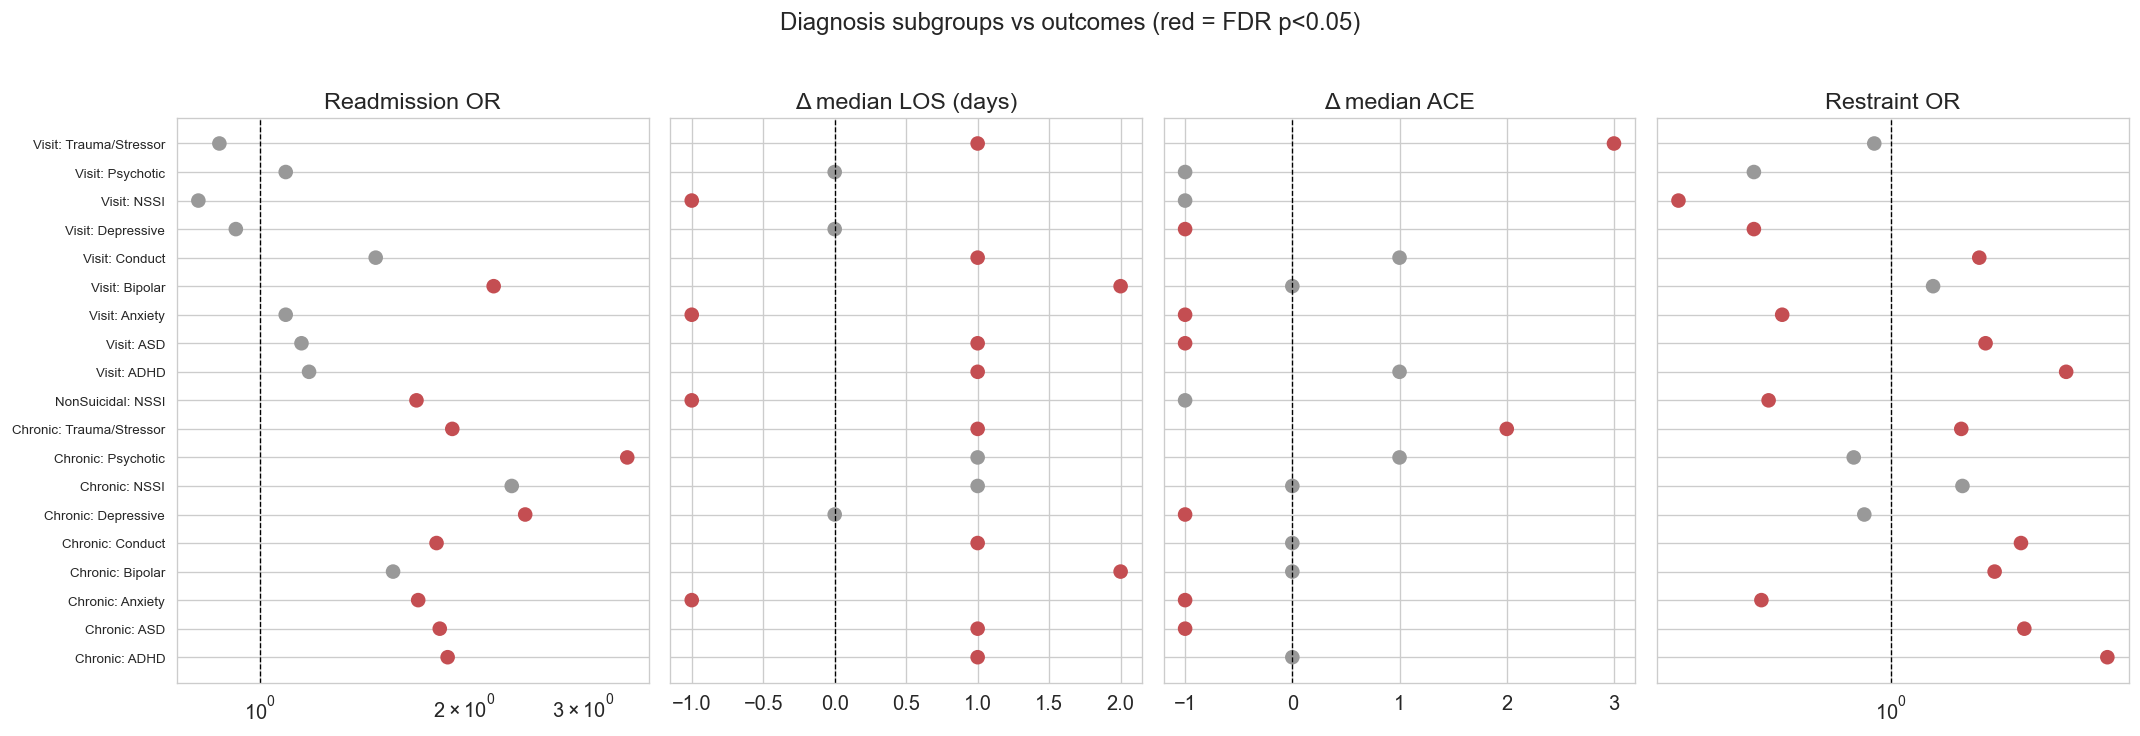

saved Sub_forest_panels.png


In [19]:
# Forest panels: subgroup vs each outcome (label = column:subgroup)
sub['lab']=sub['column']+': '+sub['subgroup']
panels=[('readmit_OR','p_readmit_fdr','Readmission OR',True),
        ('dLOS','p_los_fdr','Δ median LOS (days)',False),
        ('dACE','p_ace_fdr','Δ median ACE',False),
        ('restraint_OR','p_restraint_fdr','Restraint OR',True)]
fig,axes=plt.subplots(1,4,figsize=(18,6),sharey=True)
order=sub.sort_values(['column','subgroup']).index
for ax,(val,pf,title,islog) in zip(axes,panels):
    s=sub.loc[order]
    colors=[RED if (pd.notna(p) and p<0.05) else '0.6' for p in s[pf]]
    ax.scatter(s[val], range(len(s)), color=colors, s=60)
    ax.set_yticks(range(len(s))); ax.set_yticklabels(s['lab'], fontsize=8)
    ref = 1 if islog else 0
    ax.axvline(ref,color='k',lw=.8,ls='--')
    if islog: ax.set_xscale('log')
    ax.set_title(title)
plt.suptitle('Diagnosis subgroups vs outcomes (red = FDR p<0.05)',y=1.02)
plt.tight_layout(); plt.savefig('figures/Sub_forest_panels.png'); plt.show()
print('saved Sub_forest_panels.png')